# Tahap 3: Pemodelan Varian 1 — Dasar (`03_varian_1.ipynb`)
**Nama Anggota:** Muhammad Raffi  
**NIM:** 2488010046  
**Kelas / Paket:** Informatika 5C — Paket 5C-5 (*Students Dropout & Academic Success*)  
**Metode & Varian:** Klasifikasi *k*-Nearest Neighbors (*k*-NN) — **Varian 1 (Dasar / Tolok Ukur)**  

### Konfigurasi Varian 1:
* **Algoritma:** `KNeighborsClassifier(n_neighbors=5)` (konfigurasi standar $k = 5$, metrik jarak Euclidean).
* **Data Masukan:** Data hasil praproses dari `02_praproses.ipynb` (`data/train_processed.csv` dan `data/test_processed.csv`) yang telah melalui `OneHotEncoder` pada 9 kolom kategori nominal dan `StandardScaler` pada 27 kolom numerik/biner setelah `train_test_split` (bebas kebocoran data).
* **Tujuan:** Menjadi tolok ukur (*benchmark*) utama bagi Varian 2 (penyetelan parameter $k$) dan Varian 3 (pembanding algoritma *Naive Bayes*).

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

train_df = pd.read_csv('train_processed.csv')
test_df = pd.read_csv('test_processed.csv')

X_train = train_df.drop(columns=['Target'])
y_train = train_df['Target']

X_test = test_df.drop(columns=['Target'])
y_test = test_df['Target']

print("Ukuran X_train:", X_train.shape, "| y_train:", y_train.shape)
print("Ukuran X_test :", X_test.shape, "| y_test :", y_test.shape)

Ukuran X_train: (3539, 236) | y_train: (3539,)
Ukuran X_test : (885, 236) | y_test : (885,)


In [8]:
model_v1 = KNeighborsClassifier(n_neighbors=5)
model_v1.fit(X_train, y_train)

y_pred = model_v1.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
baseline = (y_test == 'Graduate').mean()

print("=== HASIL EVALUASI VARIAN 1: k-NN DASAR (k = 5) ===")
print(f"Baseline Kelas Mayoritas : {baseline:.4f} ({baseline*100:.2f}%)")
print(f"Akurasi Model            : {acc:.4f} ({acc*100:.2f}%)")
print(f"Peningkatan vs Baseline  : +{(acc - baseline)*100:.2f}%")
print(f"Precision (Macro)        : {prec_macro:.4f}")
print(f"Recall (Macro)           : {rec_macro:.4f}")
print(f"F1-Score (Macro)         : {f1_macro:.4f}")
print(f"F1-Score (Weighted)      : {f1_weighted:.4f}")

print("\n=== LAPORAN KLASIFIKASI PER KELAS ===")
print(classification_report(y_test, y_pred, digits=4))

=== HASIL EVALUASI VARIAN 1: k-NN DASAR (k = 5) ===
Baseline Kelas Mayoritas : 0.4994 (49.94%)
Akurasi Model            : 0.7028 (70.28%)
Peningkatan vs Baseline  : +20.34%
Precision (Macro)        : 0.6320
Recall (Macro)           : 0.6131
F1-Score (Macro)         : 0.6182
F1-Score (Weighted)      : 0.6909

=== LAPORAN KLASIFIKASI PER KELAS ===
              precision    recall  f1-score   support

     Dropout     0.7597    0.6901    0.7232       284
    Enrolled     0.3898    0.2893    0.3321       159
    Graduate     0.7466    0.8597    0.7992       442

    accuracy                         0.7028       885
   macro avg     0.6320    0.6131    0.6182       885
weighted avg     0.6867    0.7028    0.6909       885



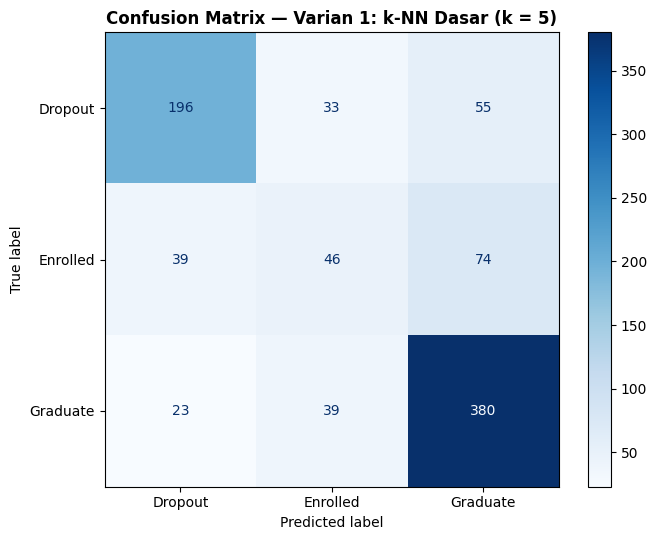

In [9]:
labels = ['Dropout', 'Enrolled', 'Graduate']
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(7, 5.5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix — Varian 1: k-NN Dasar (k = 5)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [10]:
hasil_v1 = pd.DataFrame([{
    'Varian': 'Varian 1 (Dasar)',
    'Model': 'k-NN (k=5)',
    'Akurasi': round(acc, 4),
    'Precision_Macro': round(prec_macro, 4),
    'Recall_Macro': round(rec_macro, 4),
    'F1_Macro': round(f1_macro, 4),
    'F1_Weighted': round(f1_weighted, 4)
}])

display(hasil_v1)

joblib.dump(model_v1, 'model_varian_1.pkl')

,Varian,Model,Akurasi,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted
0,Varian 1 (Dasar),k-NN (k=5),0.7028,0.632,0.6131,0.6182,0.6909


['model_varian_1.pkl']

### Analisis & Penafsiran Hasil Varian 1 (Tolok Ukur)
1. **Perbandingan terhadap Garis Dasar (*Baseline*):**
   * Model *k*-NN dasar ($k = 5$) mencapai akurasi **70,28%** (622 dari 885 data uji terprediksi tepat), meningkat **+20,34%** dibandingkan *baseline* kelas mayoritas (`Graduate` = **49,94%** pada data uji / **49,93%** pada keseluruhan dataset). Hal ini membuktikan bahwa kombinasi fitur pendaftaran dan performa semester 1–2 memiliki daya pisah yang nyata.
2. **Analisis Performa per Kelas (*Confusion Matrix*):**
   * **Kelas `Graduate` (F1-Score = 0,7992):** Memiliki performa terbaik dengan *recall* **85,97%** (380 dari 442 mahasiswa lulus berhasil dikenali dengan tepat).
   * **Kelas `Dropout` (F1-Score = 0,7232):** Berhasil mendeteksi 196 dari 284 mahasiswa putus studi (*recall* **69,01%**, *precision* **75,97%**). Namun, masih terdapat 55 mahasiswa `Dropout` yang salah diprediksi sebagai `Graduate`.
   * **Kelas `Enrolled` (F1-Score = 0,3321):** Menjadi kelas tersulit dengan *recall* hanya **28,93%** (46 dari 159 tepat). Sebanyak 74 mahasiswa `Enrolled` terprediksi sebagai `Graduate` dan 39 sebagai `Dropout`.
3. **Penyebab Terjadinya Kesalahan Klasifikasi:**
   * Sesuai temuan EDA Tahap 1, mahasiswa berstatus `Enrolled` masih aktif berkuliah saat pencatatan berakhir sehingga profil akademik semester 1–2 mereka tumpang tindih dengan mahasiswa `Graduate`.
   * Selain itu, proses *One-Hot Encoding* menghasilkan dimensi tinggi (**224 fitur**) yang dapat memengaruhi perhitungan jarak Euclidean pada *k*-NN (*curse of dimensionality*), sehingga perlu diuji nilai $k$ yang lebih besar pada **Varian 2** untuk melihat apakah batas keputusan menjadi lebih stabil.